In [ ]:
!pip install scikit-learn torch optuna pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 442.4/442.4 kB 31.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 28.4 MB/s eta 0:00:00


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.models import Sequential
import optuna

# Modelo LSTM Unidirecional - Baselines Abordagem B

Para validar a acurácia de um modelo de redes neurais recorrentes e justificar a sua utilização bem como a evolução de sua estrutura, os seguintes testes serão submetidos:

### 1. Auto-previsão do ERA5
##### ($\text{ws100_era5} \rightarrow \text{ws100_era5}$) — Abordagem B

O primeiro experimento da **Abordagem B** consiste no teste de auto-previsão autorregressiva de controle (*sanity check*), no qual o modelo é treinado para prever as tendências da própria série temporal da reanálise atmosférica ERA5 interpolada para a resolução de 10 minutos (`ws100_era5`).

O objetivo é **validar o funcionamento do pipeline em alta resolução temporal** e analisar a resposta da LSTM perante um sinal cujos pontos sub-horários foram gerados por interpolação linear.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

### Divisão Cronológica do Dataset
O dataset na resolução de 10 minutos (**Abordagem B**) contém exatos **4.195 pontos coincidentes**. Respeitando a ordem temporal cronológica para evitar vazamento de dados (*data leakage*), a base foi dividida em:
* **Treinamento (70%):** 2.936 registros (resultando em 2.792 sequências de entrada após o desconto da janela deslizante de 144 passos);
* **Validação (15%):** 629 registros (aproximadamente 485 sequências para ajuste de hiperparâmetros);
* **Teste (15%):** 630 registros (aproximadamente 486 sequências para inferência final e avaliação de métricas).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 144 *timestamps* (representando 24 horas de histórico passado na resolução de 10 minutos, pois $144 \times 10\text{ min} = 1.440\text{ min} = 24\text{h}$);
* **Tamanho do Lote (*Batch Size*):** 64 amostras, valor otimizado para o volume do conjunto de treinamento (~2.792 sequências, gerando cerca de 44 atualizações de pesos por época);
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e função de ativação $\tanh$ para captura de dependências temporais;
* **Regularização:** Camada *Dropout* com taxa de 0,2 (20%) para prevenir sobreajuste (*overfitting*);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e função de ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(HORIZON = 6)` para a previsão de passo único em resolução decaminutal ($+60\text{ min}$);
  * Camada `Dense(HORIZON = 36)` para a projeção direta do horizonte multi-passo ($+10\text{ min}$ a $+360\text{ min}$, cobrindo 6 horas à frente).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** Algoritmo *Adam* minimizando a função de perda do Erro Quadrático Médio (MSE);
* **EarlyStopping:** Interrupção automática caso a perda de validação (`val_loss`) não apresente melhoria por 7 épocas consecutivas (`patience=7`), restaurando os pesos do melhor estado (`restore_best_weights=True`);
* **ReduceLROnPlateau:** Redução da taxa de aprendizado em 50% (`factor=0.5`) caso a `val_loss` estagne por 3 épocas (`patience=3`), com limite mínimo de $1\times10^{-5}$.






[I 2026-10-20 17:45:33,447] A new study created in memory with name: no-name-bf50ce66-bd77-421e-bff4-051ad74f7b44


Formato de X_train (Amostras, Histórico, Atributos): (2779, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2779, 6)



[I 2026-10-20 17:45:52,424] Trial 0 finished with value: 0.06047121435403824 and parameters: {'lstm_units': 256, 'dense_units': 128, 'dropout_rate': 0.5, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.06047121435403824.
[I 2026-10-20 17:45:59,170] Trial 1 finished with value: 0.10757989436388016 and parameters: {'lstm_units': 128, 'dense_units': 256, 'dropout_rate': 0.4, 'learning_rate': 0.00019010245319870352, 'batch_size': 128}. Best is trial 0 with value: 0.06047121435403824.
[I 2026-10-20 17:47:24,921] Trial 2 finished with value: 0.07554218918085098 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.5, 'learning_rate': 0.00853618986286683, 'batch_size': 6}. Best is trial 0 with value: 0.06047121435403824.
[I 2026-10-20 17:47:48,629] Trial 3 finished with value: 0.05821757763624191 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.001096821720752952, 'batch_size': 64}. Bes

Melhores Hiperparâmetros: {'lstm_units': 512, 'dense_units': 512, 'dropout_rate': 0.1, 'learning_rate': 0.0006623862141828241, 'batch_size': 32}
Epoch 1/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step - loss: 0.1795 - mae: 0.3088 - val_loss: 0.0847 - val_mae: 0.2109 - learning_rate: 6.6239e-04
Epoch 2/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0784 - mae: 0.2086 - val_loss: 0.0788 - val_mae: 0.2028 - learning_rate: 6.6239e-04
Epoch 3/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0672 - mae: 0.1894 - val_loss: 0.0831 - val_mae: 0.2069 - learning_rate: 6.6239e-04
Epoch 4/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0617 - mae: 0.1789 - val_loss: 0.0697 - val_mae: 0.1865 - learning_rate: 6.6239e-04
Epoch 5/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0591 - mae: 0.1731 - val_loss: 0.0745 - val_mae: 0.1994 - learning_rate: 6.6239e-04
Epoch 6/50
87/87 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.0584 - mae: 0.1715 - val_loss: 0.0668 - val_mae: 0.1787 - learning_ra

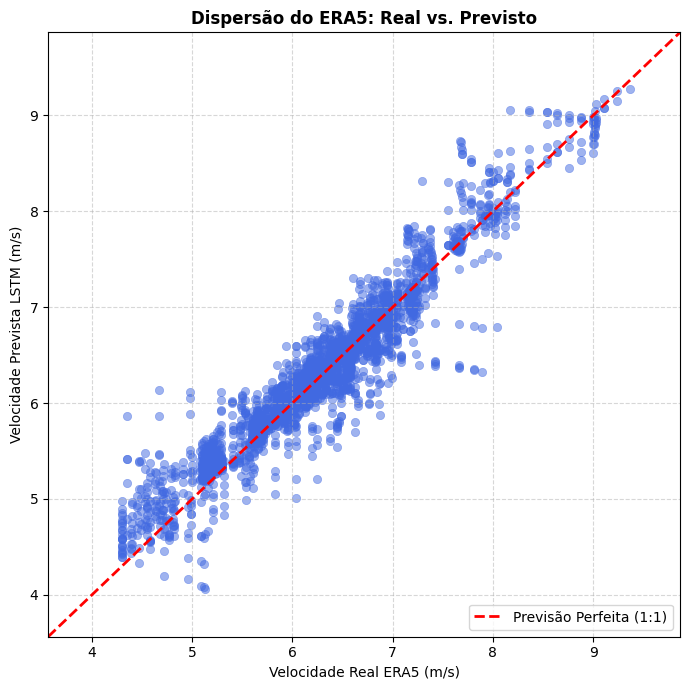

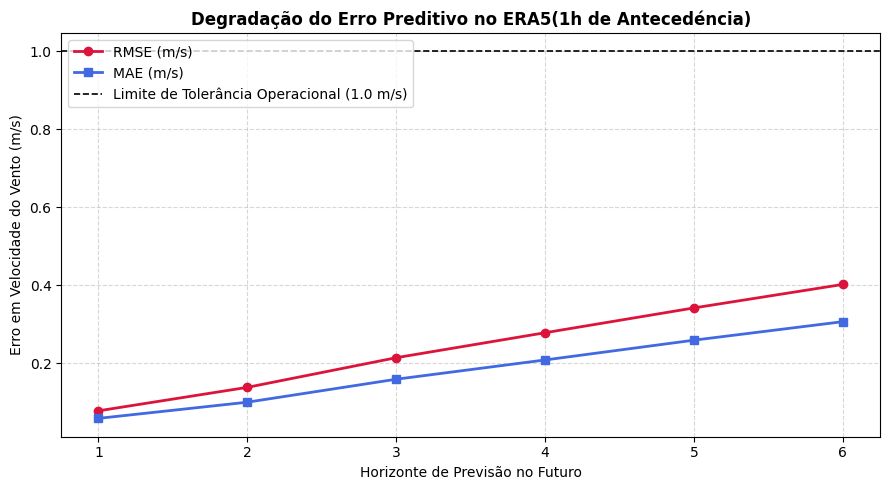

In [ ]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_b.parquet")

features = ["ws100_era5"]
target = "ws100_era5"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 6  # 1 hora de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 4. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
def build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val):
  lstm_units = trial.suggest_categorical('lstm_units', [128, 256, 512])
  dense_units = trial.suggest_categorical('dense_units', [128, 256, 512, 2048])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [6, 32, 64, 128])

  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation='tanh'),
          Dropout(dropout_rate),
          Dense(dense_units, activation='relu'),
          Dense(HORIZON),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 5. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 6. AVALIAÇÃO PASSO A PASSO (1H ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 1h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 8. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h de Antecedéncia)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

#### Ampliação do Horizonte para 6 passos:

[I 2026-10-20 18:03:01,213] A new study created in memory with name: no-name-3036d0e2-0c54-4098-aacd-b099796c0bd8


Formato de X_train (Amostras, Histórico, Atributos): (2749, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2749, 36)



[I 2026-10-20 18:03:14,584] Trial 0 finished with value: 0.4250284433364868 and parameters: {'lstm_units': 256, 'dense_units': 128, 'dropout_rate': 0.5, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.4250284433364868.
[I 2026-10-20 18:03:21,064] Trial 1 finished with value: 0.6098789572715759 and parameters: {'lstm_units': 128, 'dense_units': 256, 'dropout_rate': 0.4, 'learning_rate': 0.00019010245319870352, 'batch_size': 128}. Best is trial 0 with value: 0.4250284433364868.
[I 2026-10-20 18:04:29,179] Trial 2 finished with value: 1.9847829341888428 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.5, 'learning_rate': 0.00853618986286683, 'batch_size': 6}. Best is trial 0 with value: 0.4250284433364868.
[I 2026-10-20 18:04:53,175] Trial 3 finished with value: 0.40930283069610596 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.001096821720752952, 'batch_size': 64}. Best is t

Melhores Hiperparâmetros: {'lstm_units': 512, 'dense_units': 512, 'dropout_rate': 0.1, 'learning_rate': 0.0007296071204818504, 'batch_size': 64}
Epoch 1/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 4s 42ms/step - loss: 0.6224 - mae: 0.6126 - val_loss: 0.6053 - val_mae: 0.5955 - learning_rate: 7.2961e-04
Epoch 2/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.4847 - mae: 0.5325 - val_loss: 0.6049 - val_mae: 0.5913 - learning_rate: 7.2961e-04
Epoch 3/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.4668 - mae: 0.5216 - val_loss: 0.6057 - val_mae: 0.5776 - learning_rate: 7.2961e-04
Epoch 4/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.3828 - mae: 0.4756 - val_loss: 0.5472 - val_mae: 0.5427 - learning_rate: 7.2961e-04
Epoch 5/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - loss: 0.3542 - mae: 0.4578 - val_loss: 0.4584 - val_mae: 0.5170 - learning_rate: 7.2961e-04
Epoch 6/50
43/43 ━━━━━━━━━━━━━━━━━━━━ 2s 35ms/step - loss: 0.3457 - mae: 0.4514 - val_loss: 0.5387 - val_mae: 0.5259 - learning_ra

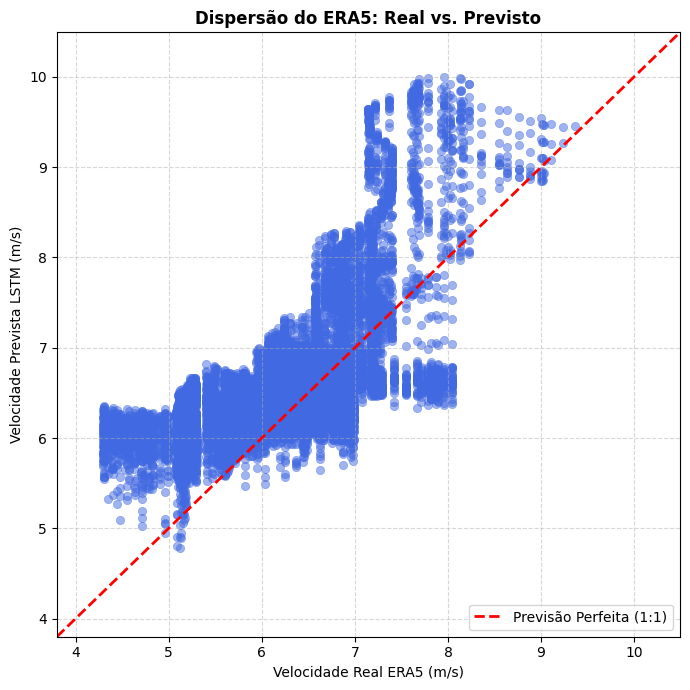

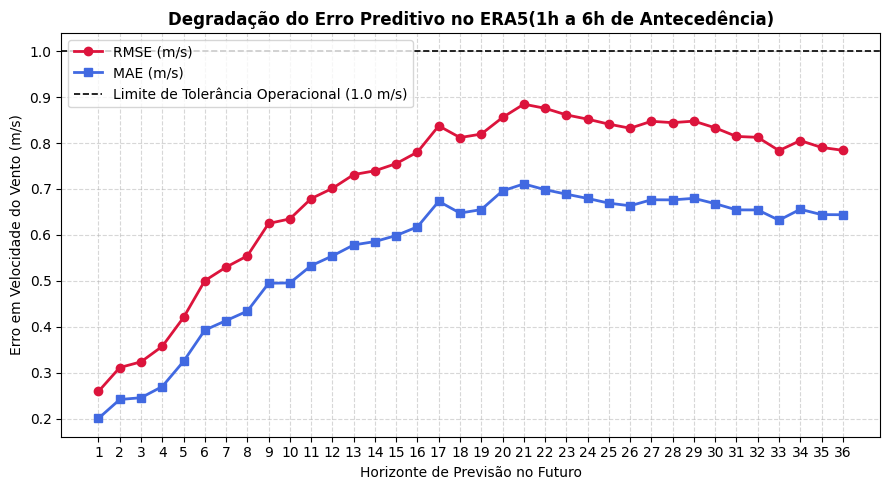

In [ ]:
# ==========================================
# 9. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# A ideia é entender se o modelo é capaz de se auto-prever em um horizonte de 6 passos
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=36):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 36  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 10. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
def build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val):
  lstm_units = trial.suggest_categorical('lstm_units', [128, 256, 512])
  dense_units = trial.suggest_categorical('dense_units', [128, 256, 512, 2048])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [6, 32, 64, 128])

  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation='tanh'),
          Dropout(dropout_rate),
          Dense(dense_units, activation='relu'),
          Dense(HORIZON),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)
# ==========================================
# 11. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 12. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 13. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 2. Previsão do Vento LiDAR Filtrado
#### ($\text{ws100_lidar_clean} \rightarrow \text{ws100_lidar}$) — Abordagem B

O segundo experimento consiste no teste autorregressivo em alta resolução temporal com sinal suavizado, no qual a LSTM é alimentada pela série temporal alinhada LiDAR/ERA5 filtrada por Wavelet (`ws100_lidar_clean`) para prever a velocidade real e instantânea do vento (`ws100_lidar`) na escala nativa de 10 minutos.

O objetivo é **avaliar a inércia de curtíssimo prazo** e medir até que ponto a filtragem Wavelet (`sym18`, nível 2) sustenta a acurácia do modelo passo a passo ao longo dos primeiros 60 minutos.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

### Divisão Cronológica do Dataset
Dataset contendo **4.195 registros** de 10 minutos. Respeitando a ordem cronológica estrita:
* **Treinamento (70%):** 2.936 registros (2.792 sequências efetivas);
* **Validação (15%):** 629 registros (485 sequências);
* **Teste (15%):** 630 registros (486 sequências).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 144 *timestamps* (24 horas de histórico em passos de 10 minutos);
* **Tamanho do Lote (*Batch Size*):** 64 amostras;
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e ativação $\tanh$;
* **Regularização:** *Dropout* de 0,2 (20%);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(HORIZON = 6)` para passo único ($+60\text{ min}$);
  * Camada `Dense(HORIZON = 36)` para projeção direta dos 6 passos ($+10\text{ min}$ a $+360\text{ min}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** *Adam* minimizando o Erro Quadrático Médio (MSE);
* **EarlyStopping:** `patience=7`, `restore_best_weights=True`;
* **ReduceLROnPlateau:** `patience=3`, `factor=0.5`, `min_lr=1e-5`.

[I 2026-10-20 18:14:14,569] A new study created in memory with name: no-name-94db3621-5a79-4fb6-822a-a020742287c1


Formato de X_train (Amostras, Histórico, Atributos): (2779, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2779, 6)



[I 2026-10-20 18:14:26,489] Trial 0 finished with value: 0.30933237075805664 and parameters: {'lstm_units': 256, 'dense_units': 128, 'dropout_rate': 0.5, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.30933237075805664.
[I 2026-10-20 18:14:33,776] Trial 1 finished with value: 0.4623781740665436 and parameters: {'lstm_units': 128, 'dense_units': 256, 'dropout_rate': 0.4, 'learning_rate': 0.00019010245319870352, 'batch_size': 128}. Best is trial 0 with value: 0.30933237075805664.
[I 2026-10-20 18:15:42,185] Trial 2 finished with value: 1.1797575950622559 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.5, 'learning_rate': 0.00853618986286683, 'batch_size': 6}. Best is trial 0 with value: 0.30933237075805664.
[I 2026-10-20 18:16:06,254] Trial 3 finished with value: 0.262259840965271 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.001096821720752952, 'batch_size': 64}. Best is

Melhores Hiperparâmetros: {'lstm_units': 128, 'dense_units': 128, 'dropout_rate': 0.1, 'learning_rate': 0.007234279845665418, 'batch_size': 64}
Epoch 1/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.4505 - mae: 0.4926 - val_loss: 0.3927 - val_mae: 0.4533 - learning_rate: 0.0072
Epoch 2/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3383 - mae: 0.4258 - val_loss: 0.3752 - val_mae: 0.4371 - learning_rate: 0.0072
Epoch 3/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.3245 - mae: 0.4152 - val_loss: 0.3302 - val_mae: 0.4043 - learning_rate: 0.0072
Epoch 4/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.2952 - mae: 0.3976 - val_loss: 0.3181 - val_mae: 0.3999 - learning_rate: 0.0072
Epoch 5/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.7969 - mae: 0.4955 - val_loss: 0.4522 - val_mae: 0.4876 - learning_rate: 0.0072
Epoch 6/50
44/44 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.4278 - mae: 0.4842 - val_loss: 0.4388 - val_mae: 0.4813 - learning_rate: 0.0072
Epoch 7/50

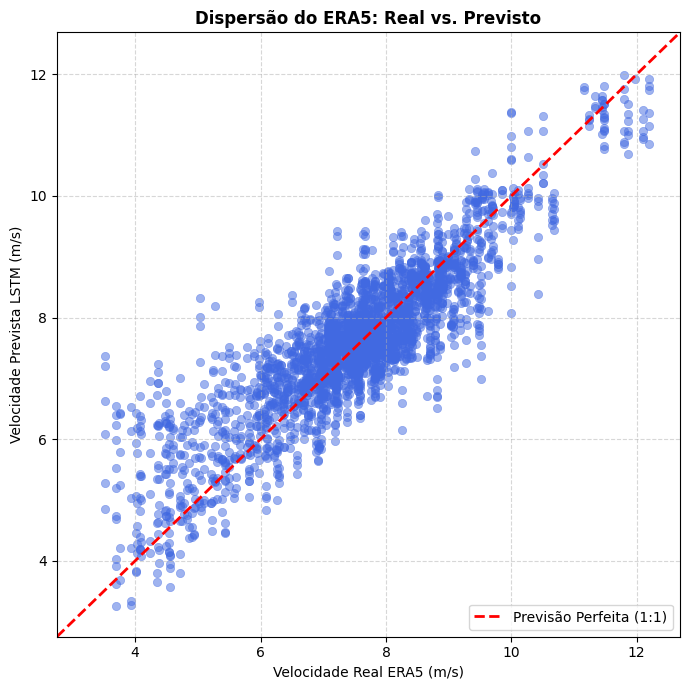

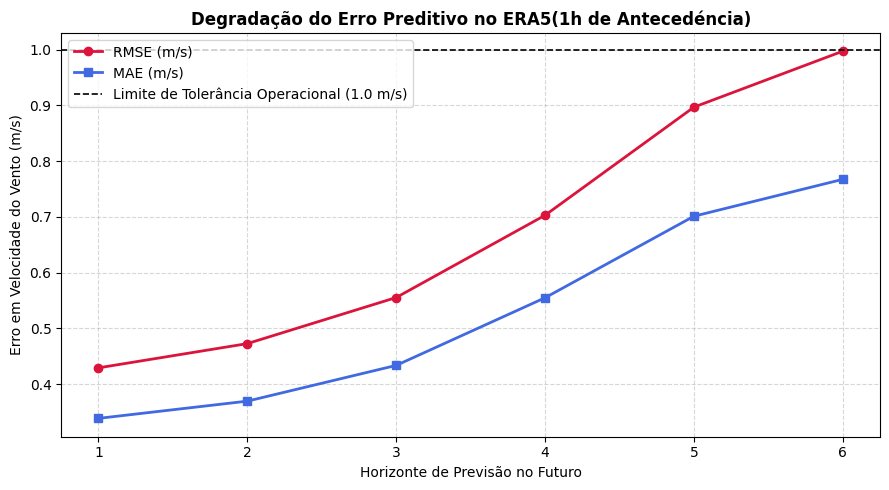

In [ ]:
# ==========================================
# 1. CARREGAMENTO E DIVISÃO TEMPORAL
# ==========================================
df = pd.read_parquet("data/approach_b.parquet")

features = ["ws100_lidar_clean"]
target = "ws100_lidar"

n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 2. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 3. JANELA DESLIZANTE (SLIDING WINDOW)
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (6) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 6  # 1 hora de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 4. MODELO LSTM MULTI-STEP
# ==========================================
def build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val):
  lstm_units = trial.suggest_categorical('lstm_units', [128, 256, 512])
  dense_units = trial.suggest_categorical('dense_units', [128, 256, 512, 2048])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [6, 32, 64, 128])

  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation='tanh'),
          Dropout(dropout_rate),
          Dense(dense_units, activation='relu'),
          Dense(HORIZON),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 5. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 6. AVALIAÇÃO PASSO A PASSO (1H ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 1h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 7. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 8. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h de Antecedéncia)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Ampliando para 6 horas

[I 2026-10-20 18:23:14,978] A new study created in memory with name: no-name-a638188b-eede-4a11-8876-7229d5c825eb


Formato de X_train (Amostras, Histórico, Atributos): (2749, 144, 1)
Formato de y_train (Amostras, Horizonte Futuro): (2749, 36)



[I 2026-10-20 18:23:22,876] Trial 0 finished with value: 0.5961501002311707 and parameters: {'lstm_units': 256, 'dense_units': 128, 'dropout_rate': 0.5, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.5961501002311707.
[I 2026-10-20 18:23:28,384] Trial 1 finished with value: 0.6921687722206116 and parameters: {'lstm_units': 128, 'dense_units': 256, 'dropout_rate': 0.4, 'learning_rate': 0.00019010245319870352, 'batch_size': 128}. Best is trial 0 with value: 0.5961501002311707.
[I 2026-10-20 18:25:19,629] Trial 2 finished with value: 1.1853229999542236 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.5, 'learning_rate': 0.00853618986286683, 'batch_size': 6}. Best is trial 0 with value: 0.5961501002311707.
[I 2026-10-20 18:25:37,058] Trial 3 finished with value: 0.594046413898468 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.001096821720752952, 'batch_size': 64}. Best is tri

Melhores Hiperparâmetros: {'lstm_units': 512, 'dense_units': 128, 'dropout_rate': 0.2, 'learning_rate': 0.00446034968148722, 'batch_size': 128}
Epoch 1/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 66ms/step - loss: 1.0698 - mae: 0.7868 - val_loss: 0.9353 - val_mae: 0.7774 - learning_rate: 0.0045
Epoch 2/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.8022 - mae: 0.6915 - val_loss: 0.7130 - val_mae: 0.6531 - learning_rate: 0.0045
Epoch 3/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.7389 - mae: 0.6592 - val_loss: 0.6430 - val_mae: 0.6161 - learning_rate: 0.0045
Epoch 4/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.7635 - mae: 0.6703 - val_loss: 0.6649 - val_mae: 0.6134 - learning_rate: 0.0045
Epoch 5/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 57ms/step - loss: 0.7276 - mae: 0.6532 - val_loss: 0.6562 - val_mae: 0.6211 - learning_rate: 0.0045
Epoch 6/50
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 56ms/step - loss: 0.7173 - mae: 0.6470 - val_loss: 0.6322 - val_mae: 0.6136 - learning_rate: 0.0045
Epoch 7/50

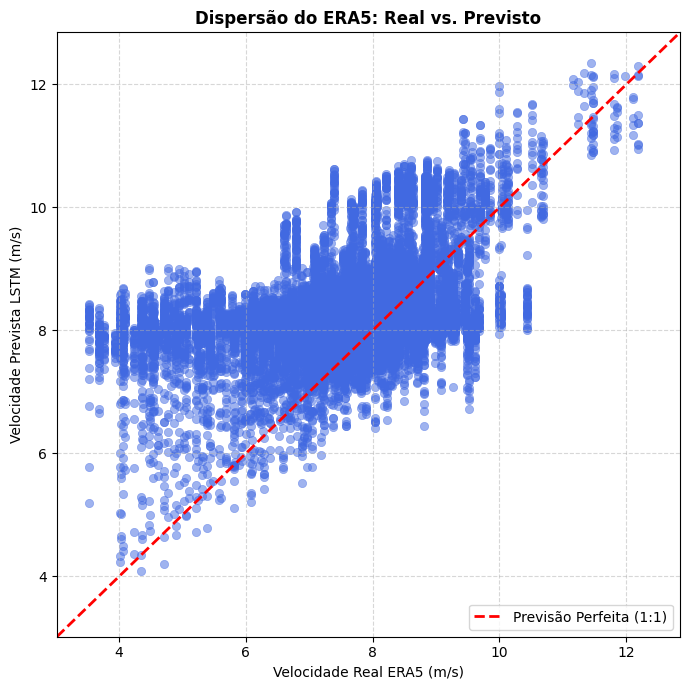

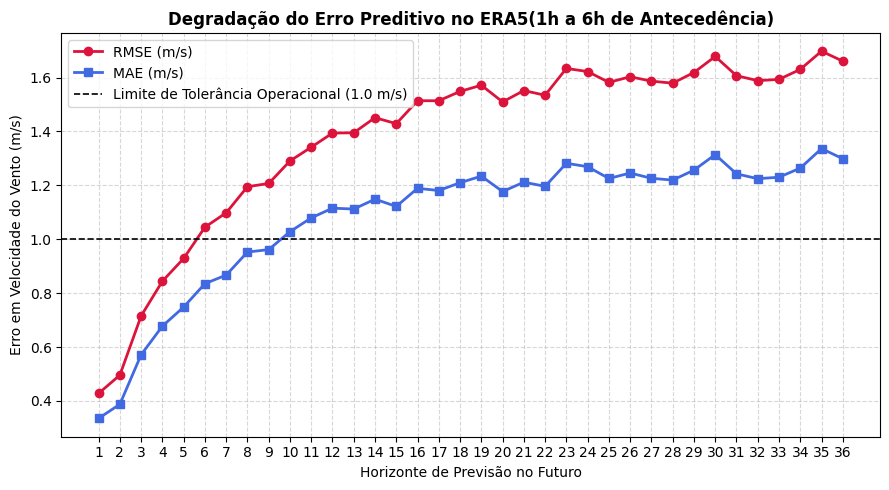

In [ ]:
# ==========================================
# 9. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# A ideia é entender se o modelo é capaz de se auto-prever em um horizonte de 6 passos
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=36):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 36  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 10. MODELO LSTM MULTI-STEP (Dense de Saída = 6)
# ==========================================
def build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val):
  lstm_units = trial.suggest_categorical('lstm_units', [128, 256, 512])
  dense_units = trial.suggest_categorical('dense_units', [128, 256, 512, 2048])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [6, 32, 64, 128])

  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation='tanh'),
          Dropout(dropout_rate),
          Dense(dense_units, activation='relu'),
          Dense(HORIZON),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 11. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 12. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 13. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 14. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

# 3. Previsão com Vetor Misto
#### ($\text{ws100_lidar_clean} + \text{ws100_era5} \rightarrow \text{ws100_lidar}$) — Abordagem B

O terceiro experimento da **Abordagem B** aborda a **fusão multivariada de dados em alta resolução**, combinando a série do LiDAR/ERA5 filtrada por Wavelet (`ws100_lidar_clean`) e a reanálise do ERA5 (`ws100_era5`) como insumos simultâneos para estimar a velocidade real (`ws100_lidar`).

O objetivo é **verificar se a amostragem de ~2.792 sequências na escala decaminutal é suficiente para estabilizar o aprendizado de atributos heterogêneos** sob uma arquitetura de camada densa direta.

A implementação dessa *baseline* segue as seguintes diretrizes metodológicas:

---

### Divisão Cronológica do Dataset
Dataset contendo **4.195 registros** de 10 minutos. Respeitando a ordem cronológica estrita:
* **Treinamento (70%):** 2.936 registros (2.792 sequências multivariadas);
* **Validação (15%):** 629 registros (485 sequências);
* **Teste (15%):** 630 registros (486 sequências).

---

### Parametrização da Arquitetura Neural
* **Histórico de Entrada (*Lookback*):** 144 *timestamps* (24 horas de histórico multivariado com 2 atributos em cada passo);
* **Tamanho do Lote (*Batch Size*):** 64 amostras;
* **Camada Recorrente:** Camada LSTM com 64 unidades ocultas e ativação $\tanh$;
* **Regularização:** *Dropout* de 0,2 (20%);
* **Processamento Densa Intermediário:** Camada *Dense* com 32 neurônios e ativação $\text{ReLU}$;
* **Camada de Saída:**
  * Camada `Dense(HORIZON = 6)` para passo único ($+60\text{ min}$);
  * Camada `Dense(HORIZON = 36)` para a projeção multi-passo ($+10\text{ min}$ a $+360\text{ min}$).

---

### Otimização e Estratégia de Controle (*Callbacks*)
* **Otimizador e Perda:** *Adam* minimizando o Erro Quadrático Médio (MSE);
* **EarlyStopping:** `patience=7`, `restore_best_weights=True`;
* **ReduceLROnPlateau:** `patience=3`, `factor=0.5`, `min_lr=1e-5`.

[I 2026-10-20 18:31:57,269] A new study created in memory with name: no-name-01ad8eb2-cee4-4955-bcc0-937d643d27f0


Formato de X_train (Amostras, Histórico, Atributos): (2779, 144, 2)
Formato de y_train (Amostras, Horizonte Futuro): (2779, 6)



[I 2026-10-20 18:32:18,410] Trial 0 finished with value: 0.3003781735897064 and parameters: {'lstm_units': 256, 'dense_units': 128, 'dropout_rate': 0.5, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.3003781735897064.
[I 2026-10-20 18:32:25,189] Trial 1 finished with value: 0.4870581030845642 and parameters: {'lstm_units': 128, 'dense_units': 256, 'dropout_rate': 0.4, 'learning_rate': 0.00019010245319870352, 'batch_size': 128}. Best is trial 0 with value: 0.3003781735897064.
[I 2026-10-20 18:34:22,380] Trial 2 finished with value: 1.1800529956817627 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.5, 'learning_rate': 0.00853618986286683, 'batch_size': 6}. Best is trial 0 with value: 0.3003781735897064.
[I 2026-10-20 18:34:47,498] Trial 3 finished with value: 0.27047044038772583 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.001096821720752952, 'batch_size': 64}. Best is t

Melhores Hiperparâmetros: {'lstm_units': 512, 'dense_units': 128, 'dropout_rate': 0.1, 'learning_rate': 0.0006076352168607445, 'batch_size': 6}
Epoch 1/50
464/464 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - loss: 0.4376 - mae: 0.4859 - val_loss: 0.4098 - val_mae: 0.4583 - learning_rate: 6.0764e-04
Epoch 2/50
464/464 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.3238 - mae: 0.4132 - val_loss: 0.3306 - val_mae: 0.4154 - learning_rate: 6.0764e-04
Epoch 3/50
464/464 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.3099 - mae: 0.4056 - val_loss: 0.3795 - val_mae: 0.4536 - learning_rate: 6.0764e-04
Epoch 4/50
464/464 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.3033 - mae: 0.3992 - val_loss: 0.3282 - val_mae: 0.4151 - learning_rate: 6.0764e-04
Epoch 5/50
464/464 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.2785 - mae: 0.3844 - val_loss: 0.3288 - val_mae: 0.4173 - learning_rate: 6.0764e-04
Epoch 6/50
464/464 ━━━━━━━━━━━━━━━━━━━━ 8s 17ms/step - loss: 0.2731 - mae: 0.3808 - val_loss: 0.3389 - val_mae: 0.4258 - 

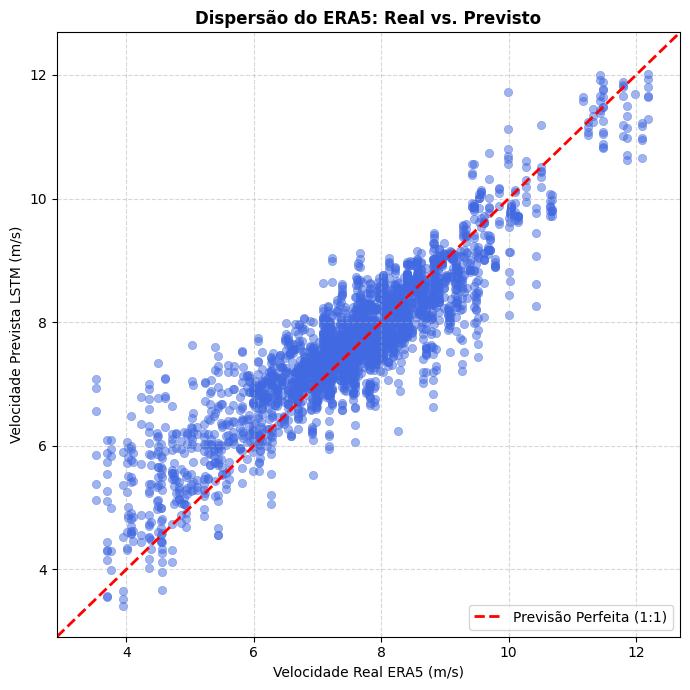

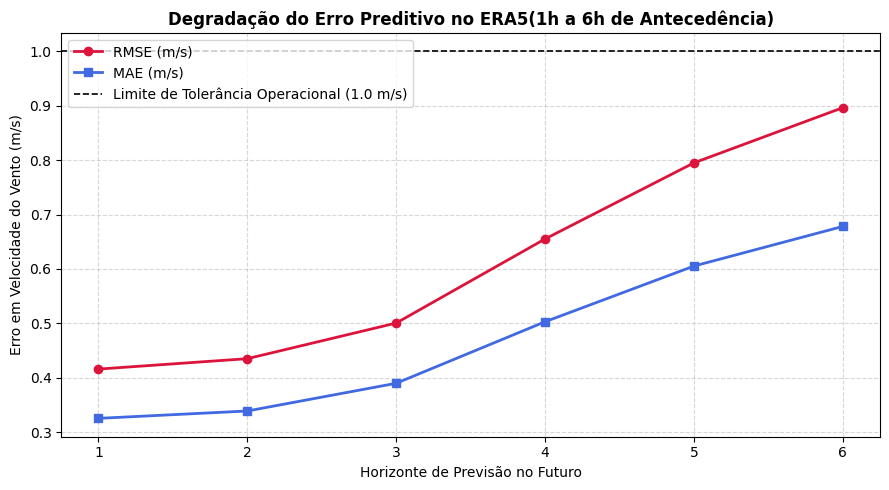

In [ ]:
# ==========================================
# 1. CARREGAMENTO E PREPARAÇÃO DOS DADOS (Abordagem B)
# ==========================================
df = pd.read_parquet("data/approach_b.parquet")

# Features de entrada (X): ERA5 e LiDAR filtrado por Wavelet
features = ["ws100_era5", "ws100_lidar_clean"]
# Alvo (Y): Verdade de campo do LiDAR
target = "ws100_lidar"

# ==========================================
# 2. DIVISÃO TEMPORAL CRONOLÓGICA (70% / 15% / 15%)
# ==========================================
n = len(df)
train_df = df.iloc[: int(n * 0.7)]
val_df = df.iloc[int(n * 0.7) : int(n * 0.85)]
test_df = df.iloc[int(n * 0.85) :]

# ==========================================
# 3. NORMALIZAÇÃO SEPARADA (X e Y)
# ==========================================
scaler_x = StandardScaler()
scaler_y = StandardScaler()

X_train_raw = scaler_x.fit_transform(train_df[features])
y_train_raw = scaler_y.fit_transform(train_df[[target]])

X_val_raw = scaler_x.transform(val_df[features])
y_val_raw = scaler_y.transform(val_df[[target]])

X_test_raw = scaler_x.transform(test_df[features])
y_test_raw = scaler_y.transform(test_df[[target]])

# ==========================================
# 4. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=6):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 6  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 5. MODELO LSTM MULTI-STEP
# ==========================================
def build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val):
  lstm_units = trial.suggest_categorical('lstm_units', [128, 256, 512])
  dense_units = trial.suggest_categorical('dense_units', [128, 256, 512, 2048])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [6, 32, 64, 128])

  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation='tanh'),
          Dropout(dropout_rate),
          Dense(dense_units, activation='relu'),
          Dense(HORIZON),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 6. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 7. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 8. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 9. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

Ampliando para 6 horas

[I 2026-10-20 18:42:41,735] A new study created in memory with name: no-name-24bb3d4b-71cc-42c4-99c0-9e7ea00eb78d


Formato de X_train (Amostras, Histórico, Atributos): (2749, 144, 2)
Formato de y_train (Amostras, Horizonte Futuro): (2749, 36)



[I 2026-10-20 18:42:50,379] Trial 0 finished with value: 0.5704709887504578 and parameters: {'lstm_units': 256, 'dense_units': 128, 'dropout_rate': 0.5, 'learning_rate': 0.0015930522616241021, 'batch_size': 64}. Best is trial 0 with value: 0.5704709887504578.
[I 2026-10-20 18:42:56,289] Trial 1 finished with value: 0.6185956597328186 and parameters: {'lstm_units': 128, 'dense_units': 256, 'dropout_rate': 0.4, 'learning_rate': 0.00019010245319870352, 'batch_size': 128}. Best is trial 0 with value: 0.5704709887504578.
[I 2026-10-20 18:44:12,588] Trial 2 finished with value: 1.184988260269165 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.5, 'learning_rate': 0.00853618986286683, 'batch_size': 6}. Best is trial 0 with value: 0.5704709887504578.
[I 2026-10-20 18:44:27,587] Trial 3 finished with value: 0.5526907444000244 and parameters: {'lstm_units': 512, 'dense_units': 256, 'dropout_rate': 0.2, 'learning_rate': 0.001096821720752952, 'batch_size': 64}. Best is tri

Melhores Hiperparâmetros: {'lstm_units': 512, 'dense_units': 128, 'dropout_rate': 0.2, 'learning_rate': 0.002878805718308925, 'batch_size': 32}
Epoch 1/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 3s 25ms/step - loss: 0.7505 - mae: 0.6624 - val_loss: 0.6120 - val_mae: 0.5801 - learning_rate: 0.0029
Epoch 2/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.6817 - mae: 0.6267 - val_loss: 0.6535 - val_mae: 0.6015 - learning_rate: 0.0029
Epoch 3/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.6479 - mae: 0.6105 - val_loss: 0.7051 - val_mae: 0.6205 - learning_rate: 0.0029
Epoch 4/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.6388 - mae: 0.6044 - val_loss: 0.5675 - val_mae: 0.5651 - learning_rate: 0.0029
Epoch 5/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.6363 - mae: 0.6036 - val_loss: 0.6095 - val_mae: 0.5844 - learning_rate: 0.0029
Epoch 6/50
86/86 ━━━━━━━━━━━━━━━━━━━━ 2s 23ms/step - loss: 0.6156 - mae: 0.5930 - val_loss: 0.5648 - val_mae: 0.5666 - learning_rate: 0.0029
Epoch 7/50

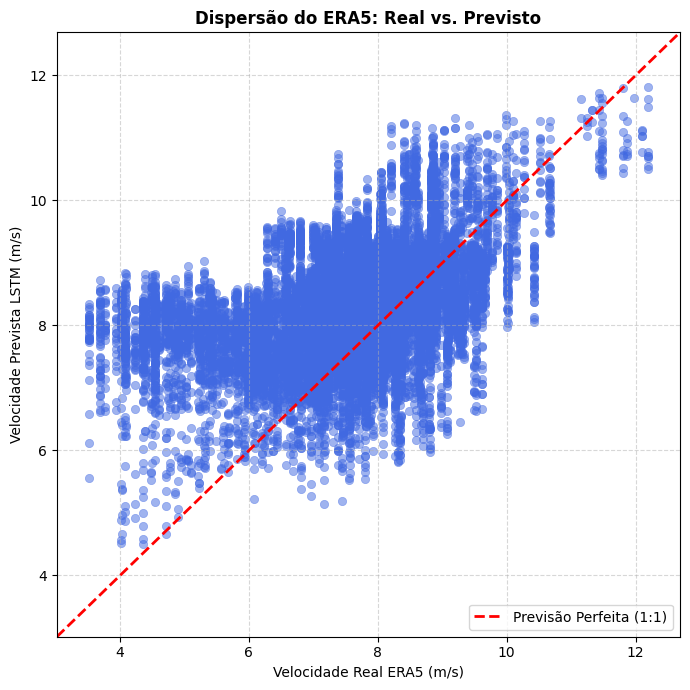

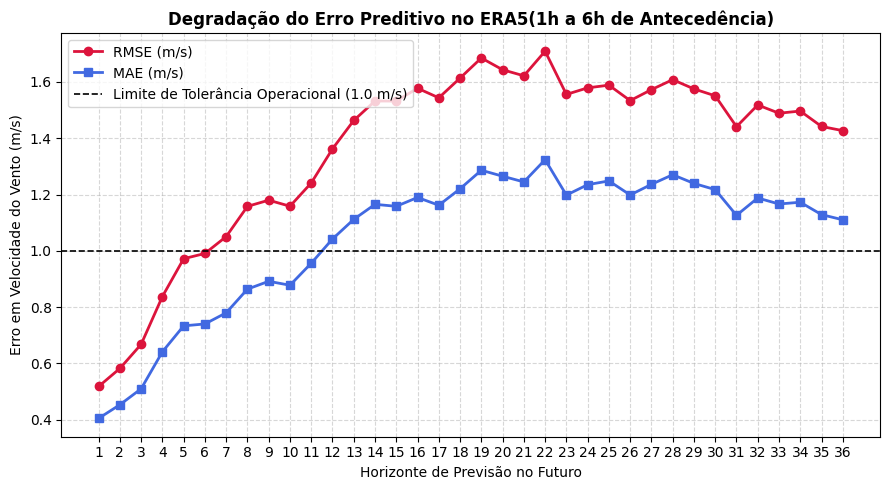

In [ ]:
# ==========================================
# 10. CRIAÇÃO DE SEQUÊNCIAS MULTI-STEP (1 passo -> 6 passos)
# A ideia é entender se o modelo é capaz de se auto-prever em um horizonte de 6 passos
# ==========================================
def create_multistep_sequences(X_data, y_data, lookback=144, horizon=36):
  X_out, y_out = [], []
  # Garante que haja pontos suficientes para cobrir o lookback E o horizonte completo
  for i in range(len(X_data) - lookback - horizon + 1):
    X_out.append(X_data[i : i + lookback, :])
    # Extrai um vetor de 'horizon' (36) valores futuros para o alvo Y
    y_out.append(y_data[i + lookback : i + lookback + horizon, 0])
  return np.array(X_out), np.array(y_out)

LOOKBACK = 144  # 24 horas de histórico passado
HORIZON = 36  # 6 horas de previsão futura

X_train, y_train = create_multistep_sequences(
    X_train_raw, y_train_raw, LOOKBACK, HORIZON
)
X_val, y_val = create_multistep_sequences(
    X_val_raw, y_val_raw, LOOKBACK, HORIZON
)
X_test, y_test = create_multistep_sequences(
    X_test_raw, y_test_raw, LOOKBACK, HORIZON
)

print(
    f"Formato de X_train (Amostras, Histórico, Atributos): {X_train.shape}"
)  # Ex: (~2056, 24, 2)
print(f"Formato de y_train (Amostras, Horizonte Futuro): {y_train.shape}\n")  # Ex: (~2056, 6)

# ==========================================
# 11. MODELO LSTM MULTI-STEP
# ==========================================
def build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val):
  lstm_units = trial.suggest_categorical('lstm_units', [128, 256, 512])
  dense_units = trial.suggest_categorical('dense_units', [128, 256, 512, 2048])
  dropout_rate = trial.suggest_float('dropout_rate', 0.1, 0.5, step=0.1)
  learning_rate = trial.suggest_float('learning_rate', 1e-4, 1e-2, log=True)
  batch_size = trial.suggest_categorical('batch_size', [6, 32, 64, 128])

  model = Sequential(
      [
          Input(
              shape=(X_train.shape[1], X_train.shape[2])
          ),
          LSTM(lstm_units, activation='tanh'),
          Dropout(dropout_rate),
          Dense(dense_units, activation='relu'),
          Dense(HORIZON),
      ]
  )
  optimizer = tf.keras.optimizers.Adam(learning_rate=learning_rate)
  model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

  # Callbacks de controle
  early_stop = EarlyStopping(
      monitor="val_loss", patience=7, restore_best_weights=True
  )
  reduce_lr = ReduceLROnPlateau(
      monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5
  )

  history = model.fit(
      X_train,
      y_train,
      validation_data=(X_val, y_val),
      epochs=15,
      batch_size=batch_size,
      callbacks=[early_stop, reduce_lr],
      verbose=0,
  )

  # Retorna o menor erro obtido no conjunto de validação
  val_loss = min(history.history['val_loss'])
  return val_loss

# 5. Função Objetivo do Optuna
def objective(trial):
  return build_and_evaluate_model_b(trial, X_train, y_train, X_val, y_val)

# 6. Execução do Estudo do Optuna
study = optuna.create_study(
    direction='minimize',
    sampler=optuna.samplers.TPESampler(seed=42),
)

study.optimize(objective, n_trials=15)

best_params = study.best_params
print("Melhores Hiperparâmetros:", best_params)

model = Sequential([
    Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(best_params['lstm_units'], activation='tanh'),
    Dropout(best_params['dropout_rate']),
    Dense(best_params['dense_units'], activation='relu'),
    Dense(HORIZON),
])

optimizer = tf.keras.optimizers.Adam(learning_rate=best_params['learning_rate'])
model.compile(optimizer=optimizer, loss='mse', metrics=['mae'])

early_stop = EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)

model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=best_params['batch_size'],
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

# ==========================================
# 12. INFERÊNCIA E DESSESCALONAMENTO MATRICIAL
# ==========================================
y_pred_scaled = model.predict(X_test)  # Formato: (N_test, 6)

# Desescalonamento seguro de matrizes (N_test, 6) com scaler_y treinado em 1 coluna
y_real = scaler_y.inverse_transform(y_test.reshape(-1, 1)).reshape(-1, HORIZON)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).reshape(
    -1, HORIZON
)
# ==========================================
# 13. AVALIAÇÃO PASSO A PASSO (1H ATÉ 6H DE ANTECEDÊNCIA)
# ==========================================
print("\n========================================================")
print("   AVALIAÇÃO MULTI-STEP:(HORIZONTE 1H A 6H)")
print("========================================================")

rmse_per_step = []
mae_per_step = []

for step in range(HORIZON):
  step_real = y_real[:, step]
  step_pred = y_pred[:, step]

  rmse_step = np.sqrt(mean_squared_error(step_real, step_pred))
  mae_step = mean_absolute_error(step_real, step_pred)
  r2_step = r2_score(step_real, step_pred)

  rmse_per_step.append(rmse_step)
  mae_per_step.append(mae_step)

  print(
      f"Horizonte t{step+1} -> RMSE: {rmse_step:.3f} m/s | MAE: {mae_step:.3f}"
      f" m/s | R²: {r2_step:.3f}"
  )

# Métricas Globais (Média de todo o horizonte)
rmse_global = np.sqrt(mean_squared_error(y_real, y_pred))
mae_global = mean_absolute_error(y_real, y_pred)
r2_global = r2_score(y_real.flatten(), y_pred.flatten())

print("--------------------------------------------------------")
print(
    f"MÉTRICA GLOBAL (Média 6h) -> RMSE: {rmse_global:.3f} m/s | MAE:"
    f" {mae_global:.3f} m/s | R²: {r2_global:.3f}"
)
print("========================================================\n")

# ==========================================
# 14. GRÁFICO DE DISPERSÃO (1:1 SCATTER PLOT)
# ==========================================
plt.figure(figsize=(7, 7))
sns.scatterplot(
    x=y_real.flatten(), y=y_pred.flatten(), alpha=0.5, color="royalblue", edgecolor=None
)

# Definição dos limites e linha de perfeição 1:1
min_val = min(y_real.min(), y_pred.min()) - 0.5
max_val = max(y_real.max(), y_pred.max()) + 0.5

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    lw=2,
    label="Previsão Perfeita (1:1)",
)
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)
plt.title("Dispersão do ERA5: Real vs. Previsto", fontsize=12, fontweight="bold")
plt.xlabel("Velocidade Real ERA5 (m/s)", fontsize=10)
plt.ylabel("Velocidade Prevista LSTM (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# ==========================================
# 15. GRÁFICO DE DEGRADAÇÃO DO ERRO POR HORIZONTE
# ==========================================
plt.figure(figsize=(9, 5))
steps_labels = [f"{i+1}" for i in range(HORIZON)]

plt.plot(
    steps_labels,
    rmse_per_step,
    marker="o",
    color="crimson",
    linewidth=2,
    label="RMSE (m/s)",
)
plt.plot(
    steps_labels,
    mae_per_step,
    marker="s",
    color="royalblue",
    linewidth=2,
    label="MAE (m/s)",
)

plt.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1.2,
    label="Limite de Tolerância Operacional (1.0 m/s)",
)

plt.title(
    "Degradação do Erro Preditivo no ERA5(1h a 6h de Antecedência)",
    fontsize=12,
    fontweight="bold",
)
plt.xlabel("Horizonte de Previsão no Futuro", fontsize=10)
plt.ylabel("Erro em Velocidade do Vento (m/s)", fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

### Conclusões
